# Разведочный анализ данных: начало

Мы будем работать с датасетом про алмазы - в нем содержатся их различные характеристики, а также стоимость.

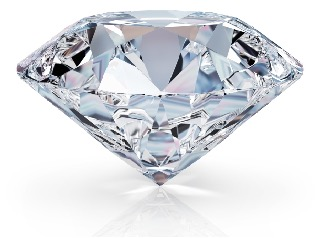

[Интересная статья про качество алмазов](https://www.diamonds.pro/education/diamond-depth-and-table/)

**Цели на сегодня:**

* понять влияние различных характеристик алмазов на их качество и стоимость

* научиться делать разведочный анализ данных

* изучить библиотеки pandas, numpy и matplotlib, seaborn

[Pandas cheatsheet](https://images.datacamp.com/image/upload/v1676302204/Marketing/Blog/Pandas_Cheat_Sheet.pdf)

## Импорт библиотек и загрузка данных

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

In [ ]:
#DIAMONDS_DATASET = "/content/drive/MyDrive/data/eda/diamonds_good.csv"

In [ ]:
df = pd.read_csv('/content/diamonds_good.csv')

## Описание данных

* `carat` - число каратов алмаза
* `cut` - огранка алмаза
* `color` - цвет алмаза
* `clarity` - прозрачность алмаза
* `depth` - глубина алмаза
* `table` - платформа алмаза (грань, которую можно увидеть, если смотреть на камень лицевой стороной вверх)
* `price` - цена алмаза
* `x` - размер алмаза по оси x
* `y` - размер алмаза по оси y
* `z` - размер алмаза по оси z

In [ ]:
df.head(10)

,carat,cut,color,clarity,depth,table,price,'x','y','z'
0,0.23,Ideal,E,SI2,61.5,55.0,326.0,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326.0,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327.0,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334.0,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335.0,4.34,4.35,2.75
5,NaN,Very Good,J,VVS2,62.8,57.0,336.0,3.94,3.96,2.48
6,0.24,Very Good,I,VVS1,62.3,57.0,336.0,3.95,3.98,2.47
7,0.26,Very Good,H,SI1,61.9,55.0,337.0,4.07,4.11,2.53
8,0.22,Fair,E,VS2,65.1,61.0,337.0,3.87,3.78,2.49
9,0.23,Very Good,H,VS1,59.4,61.0,338.0,4.00,4.05,2.39


In [ ]:
df.tail()

,carat,cut,color,clarity,depth,table,price,'x','y','z'
53935,0.72,Ideal,D,SI1,60.8,57.0,2757.0,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757.0,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757.0,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757.0,6.15,6.12,3.74
53939,0.75,Ideal,D,SI2,62.2,55.0,2757.0,5.83,5.87,3.64


In [ ]:
df.sample(3)

,carat,cut,color,clarity,depth,table,price,'x','y','z'
27454,2.30,Ideal,H,SI2,62.6,54.0,18108.0,8.42,8.46,5.28
2419,0.91,Fair,H,SI1,NaN,57.0,3180.0,6.12,6.07,3.95
50817,0.71,Ideal,G,SI1,61.1,57.0,2307.0,5.79,5.73,3.52


## Исследование данных

Размер датасета

In [ ]:
df.shape

(53940, 10)

Информация о типах данных и пропусках

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53442 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    52950 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  float64
 7   'x'      53940 non-null  float64
 8   'y'      53935 non-null  float64
 9   'z'      53940 non-null  float64
dtypes: float64(7), object(3)
memory usage: 4.1+ MB


Основные числовые характеристики

In [ ]:
df.describe()

,carat,depth,table,price,'x','y','z'
count,53442.000000,52950.000000,53940.000000,53940.000000,53940.000000,53935.000000,53940.000000
mean,0.797561,61.749422,57.457184,3932.799722,5.731157,5.734469,3.538734
std,0.473534,1.431558,2.234491,3989.439738,1.121761,1.142125,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [ ]:
df.describe(include='object')

,cut,color,clarity
count,53940,53940,53940
unique,6,7,8
top,Ideal,G,SI1
freq,21524,11292,13065


In [ ]:
df.describe(include='all')

,carat,cut,color,clarity,depth,table,price,'x','y','z'
count,53442.000000,53940,53940,53940,52950.000000,53940.000000,53940.000000,53940.000000,53935.000000,53940.000000
unique,NaN,6,7,8,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Ideal,G,SI1,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,21524,11292,13065,NaN,NaN,NaN,NaN,NaN,NaN
mean,0.797561,NaN,NaN,NaN,61.749422,57.457184,3932.799722,5.731157,5.734469,3.538734
std,0.473534,NaN,NaN,NaN,1.431558,2.234491,3989.439738,1.121761,1.142125,0.705699
min,0.200000,NaN,NaN,NaN,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,NaN,NaN,NaN,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,NaN,NaN,NaN,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,NaN,NaN,NaN,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000


In [ ]:
df.duplicated().sum()

np.int64(135)

In [ ]:
# df[условие фильтрации]

In [ ]:
df[df.duplicated()]

,carat,cut,color,clarity,depth,table,price,'x','y','z'
1005,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
1006,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
1007,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
1008,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
2025,1.52,Good,E,I1,57.3,58.0,3105.0,7.53,7.42,4.28
...,...,...,...,...,...,...,...,...,...,...
47969,0.52,Ideal,D,VS2,61.8,55.0,1919.0,5.19,5.16,3.20
49326,0.51,Ideal,F,VVS2,61.2,56.0,2093.0,5.17,5.19,3.17
49557,0.71,Good,F,SI2,64.1,60.0,2130.0,0.00,0.00,0.00
50079,0.51,Ideal,F,VVS2,61.2,56.0,2203.0,5.19,5.17,3.17


In [ ]:
# df = df.drop_duplicates()

df.drop_duplicates(inplace=True)

df.shape

(53805, 10)

In [ ]:
df.reset_index(inplace=True, drop=True)

df.head()

,carat,cut,color,clarity,depth,table,price,'x','y','z'
0,0.23,Ideal,E,SI2,61.5,55.0,326.0,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326.0,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327.0,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334.0,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335.0,4.34,4.35,2.75


In [ ]:
df.head()

,carat,cut,color,clarity,depth,table,price,'x','y','z'
0,0.23,Ideal,E,SI2,61.5,55.0,326.0,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326.0,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327.0,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334.0,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335.0,4.34,4.35,2.75


## Работа с пропущенными значениями

Стратегии заполнения пропусков:

* если пропусков очень мало (~меньше процента) - строки с пропусками можно удалить или заполнить средним/медианой

* если пропусков мало (~5-10%) - их можно заполнить (средним, медианой, уникальным значением, самым популярным значением, спрогнозировать)

* если пропусков много - можно удалить столбец

* можно пытаться предсказывать пропуски моделью

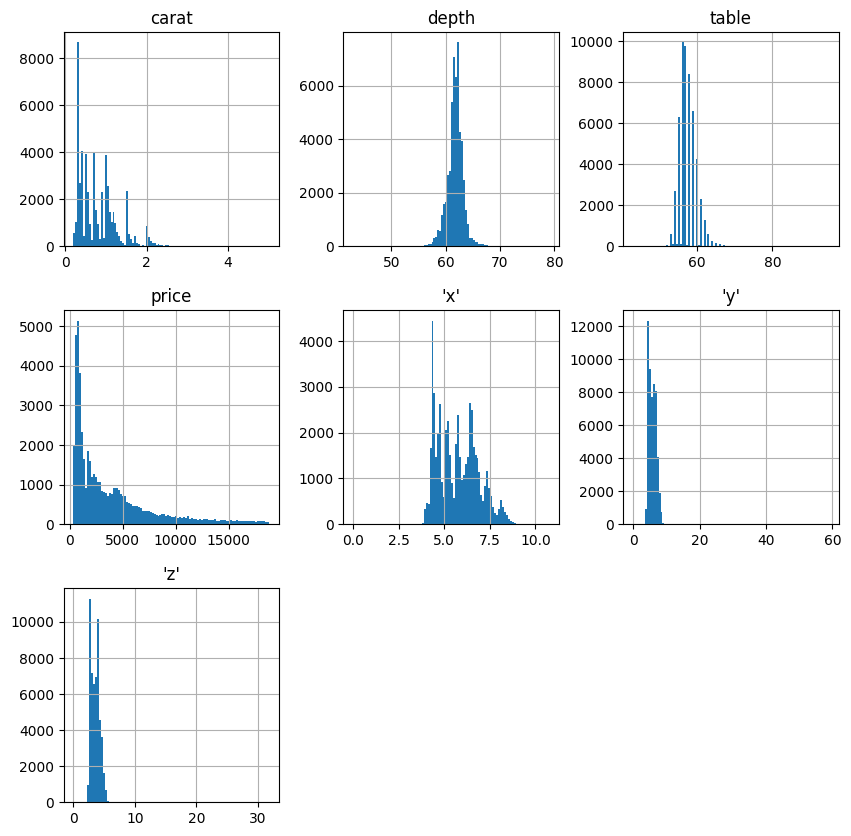

In [ ]:
df[["carat","depth","table","price","'x'","'y'","'z'"]].hist(bins=100, figsize=(10,10));

In [ ]:
median_carat = df['carat'].median()

df.fillna({'carat': median_carat}, inplace=True)

In [ ]:
median_depth = df['depth'].median()

df['depth'].fillna(median_depth, inplace=True)

/tmp/ipykernel_424/2155475674.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['depth'].fillna(median_depth, inplace=True)


### Задание 1

Заполните пропуски в столбце `y` медианным значением. Чему равно это значение? Ответ округлите до сотых.

In [ ]:
y_median = df["'y'"].median()
df["'y'"].fillna(y_median, inplace=True)

/tmp/ipykernel_424/2949047747.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["'y'"].fillna(y_median, inplace=True)


In [ ]:
y_median

5.71

## Однофакторный анализ

### Число карат

* мелкие — массой до 0,30 карат (не включительно);
* средние — массой от 0,30 до 1 карат (не включительно);
* крупные – 1 карат и выше, называют солитеры.


Небольшие бриллианты различного размера, полученные при огранке алмаза, и весящие каждый в отдельности менее 0,25 карат, называют *melee (мили)*. Полученные таким же путем более крупные бриллианты различного размера называют *melange (меланж)*.


Бриллианты более 6 карат обычно продаются c аукционов.


Алмазам и бриллиантам более 25 карат присваивают собственные имена.

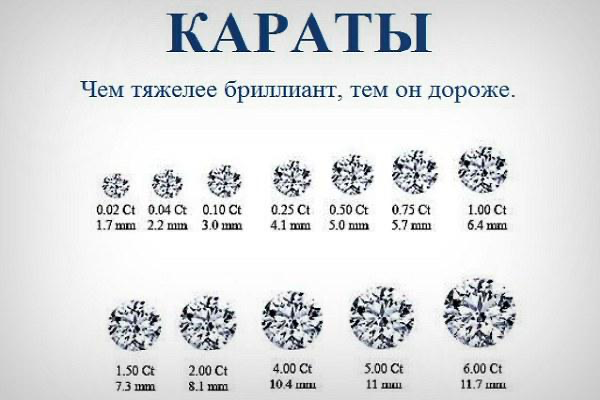

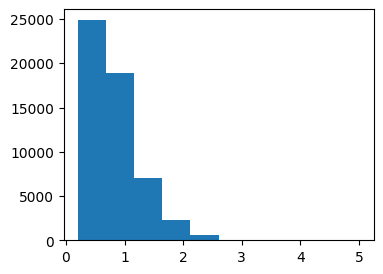

In [ ]:
plt.figure(figsize=(4,3))

plt.hist(df.carat);

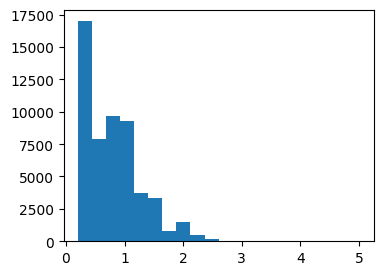

In [ ]:
plt.figure(figsize=(4,3))

plt.hist(df.carat, bins=20);

Сколько карат весит самый тяжелый бриллиант в датасете? А самый легкий?

In [ ]:
df.carat.min(), df.carat.max()

(0.2, 5.01)

Сколько мелких бриллиантов в датасете?

In [ ]:
len(df[df.carat < 0.3])

1582

Сколько процентов бриллиантов среди всего датасета - крупные?

In [ ]:
100 * len(df[df.carat >= 1]) / len(df)

35.00046464083264

Посмотрим как число карат влияет на стоимость алмаза

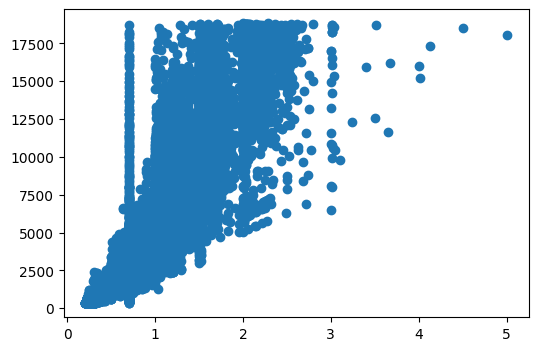

In [ ]:
plt.figure(figsize=(6,4))

plt.scatter(df.carat, df.price);

In [ ]:
np.corrcoef(df.carat, df.price)[0][1]

np.float64(0.9164989435440221)

### Cut (огранка алмаза)

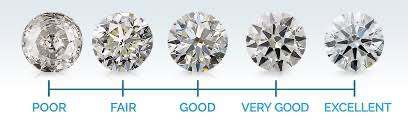

In [ ]:
df['cut'].value_counts(normalize=True)

,proportion
cut,
Ideal,0.398941
Premium,0.255088
Very Good,0.224013
Good,0.090772
Fair,0.029700
Goood,0.001487


In [ ]:
df['cut'] = df['cut'].replace('Goood', 'Good')

Посмотрим как влияет огранка алмаза на его стоимость

/tmp/ipykernel_424/1625806102.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='cut', y='price', data = df, palette='summer')


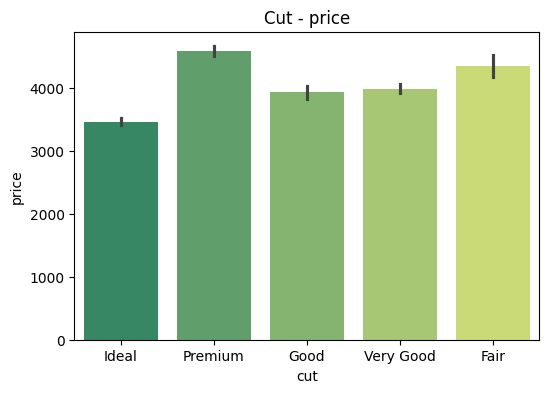

In [ ]:
plt.figure(figsize=(6,4))

sns.barplot(x='cut', y='price', data = df, palette='summer')
plt.title('Cut - price')
plt.show();

### Задание 2

Какое максимальное число карат весит алмаз огранки `Fair`?
Ответ округлите до сотых.

In [ ]:
res = df.loc[df['cut'] == 'Fair', 'carat'].max()
res

5.01

Посчитаем среднюю стоимость алмазов в каждой категории

In [ ]:
df.groupby('cut')['price'].mean()

,price
cut,
Fair,4347.735294
Good,3926.266317
Ideal,3462.593850
Premium,4581.864918
Very Good,3982.162781


Посчитаем несколько характеристик в зависимости от огранки

In [ ]:
df.groupby('cut').agg(PriceMean=('price','mean'),
                      PriceMedian=('price', 'median'),
                      CaratMean=('carat', 'mean'))

,PriceMean,PriceMedian,CaratMean
cut,,,
Fair,4347.735294,3282.0,1.040094
Good,3926.266317,3029.5,0.845796
Ideal,3462.593850,1813.0,0.703331
Premium,4581.864918,3175.0,0.889616
Very Good,3982.162781,2649.0,0.804177


In [ ]:
df.groupby('cut').agg(PriceMean=('price','mean'),
                      PriceMedian=('price', 'median'),
                      CaratMean=('carat', 'mean')).sort_values(by='PriceMean', ascending=False)

,PriceMean,PriceMedian,CaratMean
cut,,,
Premium,4581.864918,3175.0,0.889616
Fair,4347.735294,3282.0,1.040094
Very Good,3982.162781,2649.0,0.804177
Good,3926.266317,3029.5,0.845796
Ideal,3462.593850,1813.0,0.703331


## Table and Depth

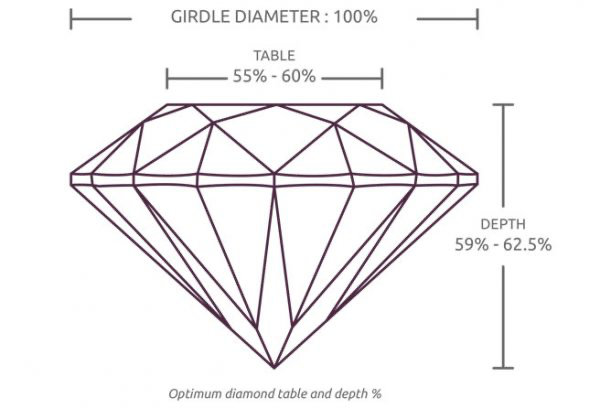

Оптимальное значение параметра `table` для алмаза [55%; 60%].

Какая доля алмазов в данных имеют оптимальное значение `table`?

In [ ]:
len(df[(df.table >= 55) & (df.table <= 60)]) / len(df)

0.8439364371340954

### Задание 3

Оптимальное значение параметра `depth` для алмаза [59%; 62.5%].

Какая доля алмазов в данных имеют одновременно оптимальное значение `table` и `depth`?

Ответ округлите до сотых.

In [ ]:
res = len(df[(df.depth >= 59) & (df.depth <= 62.5) & (df.table >= 55) & (df.table <= 60)]) / len(df)
round(res,2)

0.62

### Задание 4

Сравните медианную стоимость всех алмазов, и алмазов с оптимальными table & depth. Какая больше?

In [ ]:
print(df['price'].median())


RES = df.loc[(df.depth >= 59) & (df.depth <= 62.5) & (df.table >= 55) & (df.table <= 60), 'price'].median()
print(RES)

2401.0
2215.0


Вычислите корреляцию `table` и `price`, а затем `depth`и `price`. Какой параметр влияет на цену больше?

In [ ]:
np.corrcoef(df.table, df.price)[0][1]

np.float64(0.12662153885758198)

In [ ]:
np.corrcoef(df.depth, df.price)[0][1]

np.float64(-0.010831614226837217)

## Clarity - прозрачность алмаза

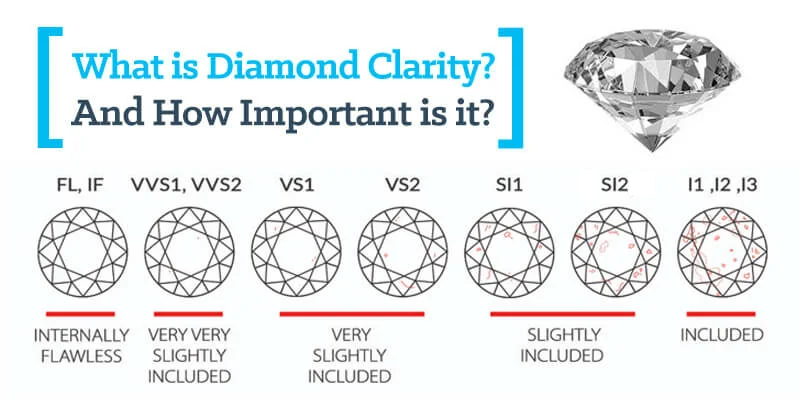

### Задание 5

Сколько различных градаций есть в столбце `clarity`?

In [ ]:
print(df['clarity'].unique())
print(len(df['clarity'].unique()))



['SI2' 'SI1' 'VS1' 'VS2' 'VVS2' 'VVS1' 'I1' 'IF']
8


### Задание 6

Сколько алмазов в таблице, относящихся к категории `very very slightly included`?

In [ ]:
len(df[(df['clarity'] == 'VVS1') | (df['clarity'] == 'VVS2')])


8704

### Задание 7

Нарисуйте график зависимости цены алмазов от `clarity`. Алмазы какой категории в наших данных стоят дороже остальных?

<Axes: xlabel='clarity', ylabel='price'>

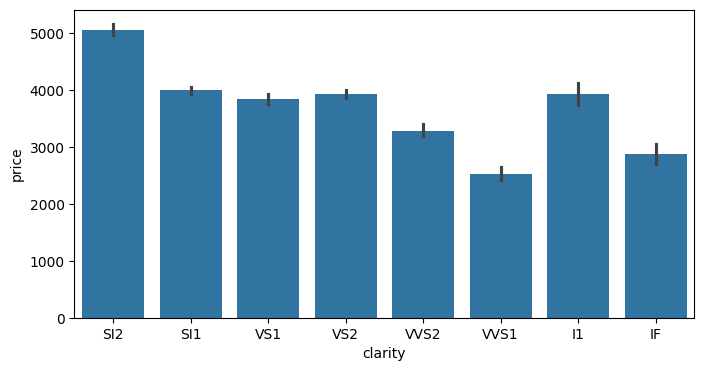

In [ ]:
plt.figure(figsize=(8, 4))
sns.barplot(x='clarity', y='price', data=df)

SI2

### Задание 8

Для каждой пары значений категорий (`cut`,`clarity`) вычислим среднюю и медианную стоимость. Результат отсортируем по убыванию средней стоимости.

Алмазы какой огранки (`cut`) в совокупностью с некоторой категорией `clarity` имеют наибольшую среднюю стоимость?

In [ ]:
res = df.groupby(['cut', 'clarity'])['price'].agg(['mean', 'median'])
res = res.sort_values(by='mean', ascending=False)
res

mean  median
cut       clarity                     
Premium   SI2      5556.262491  4292.5
Fair      SI2      5145.740175  3681.0
Very Good SI2      4988.709447  4042.0
Ideal     SI2      4761.711917  4068.0
Good      SI2      4544.119816  3763.0
Premium   VS2      4539.441053  2724.0
          VS1      4491.247730  2362.0
          SI1      4451.865244  3618.0
Very Good IF       4373.299625  1708.0
Ideal     I1       4335.726027  3673.5
Good      VS2      4280.315631  3220.5
Very Good VS2      4217.842758  2727.0
Fair      SI1      4201.818182  3511.0
          VS2      4189.217054  3202.5
          VS1      4165.141176  2829.5
Good      IF       4141.931507  1806.0
Very Good I1       4078.226190  3283.0
Premium   I1       3947.331707  3261.0
Very Good SI1      3936.972136  2810.0
Fair      VVS1     3871.352941  2797.0
Premium   IF       3856.143478  1148.0
Very Good VS1      3805.480813  2326.5
Good      VS1      3799.741248  2427.0
Premium   VVS2     3784.643599  1334.0
Ideal     SI1      3755.110434  2537.0
Fair      I1       3703.533333  2397.0
Good      SI1      3688.387015  2723.0
          I1       3601.810526  3127.0
Ideal     VS1      3490.985179  1815.0
Fair      VVS2     3349.768116  2484.0
Ideal     VS2      3290.504851  1689.0
          VVS2     3256.055212  1334.0
Good      VVS2     3118.108108  1866.5
Very Good VVS2     3037.394652  1032.0
Premium   VVS1     2834.611382  1115.0
Ideal     VVS1     2474.090240  1114.0
Very Good VVS1     2451.883249   941.0
Ideal     IF       2279.618257  1020.0
Good      VVS1     2272.391534   977.0
Fair      IF       1912.333333  1849.0

## Pandas profiling

In [ ]:
# !pip install ydata_profiling
!pip install https://github.com/pandas-profiling/pandas-profiling/archive/master.zip -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from ydata_profiling import ProfileReport

/tmp/ipykernel_424/44057814.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [ ]:
df_copy = pd.read_csv('/content/diamonds_good.csv')

profile_report = ProfileReport(df_copy, title='Pandas Profiling Report')

In [ ]:
profile_report

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 10/10 [00:00<00:00, 19.39it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
profile_report.to_file('Diamonds_report.html')

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

# Домашнее задание

## 1) x, y, z

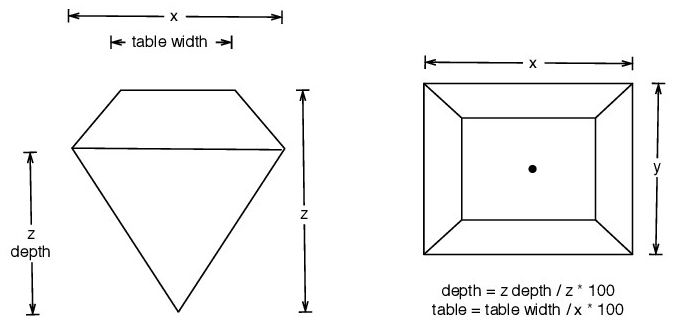

In [ ]:
df.columns

Index(['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', ''x'',
       ''y'', ''z''],
      dtype='object')

Переименуем колонки

In [ ]:
df = df.rename(columns={"'x'" : 'x', "'y'" : 'y', "'z'" : 'z'})
df.columns

Index(['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y',
       'z'],
      dtype='object')

### Задание 1

Для каждого из трех столбцов (`x`, `y`, `z`) вычислите медианное значение. В ответ запишите максимальное из полученных чисел без округлений.

In [ ]:
print(df['x'].median())
print(df['y'].median())
print(df['z'].median())



5.7
5.71
3.53


Для каждого из этих столбцов вычислите минимальное значение.

In [ ]:
res_x = df[df['x'] > 0]['x'].min()
print(res_x)

res_y = df[df['y'] > 0]['y'].min()
print(res_y)

res_z = df[df['z'] > 0]['z'].min()
print(res_z)



3.73
3.68
1.07


Нулевые размеры - явно ошибки.

### Задание 2

Выведите на экран все строки таблицы (только столбцы `x`,`y`,`z`), в которых хотя бы одна из координат равна нулю.

Сколько таких строк?

In [ ]:
len(df.loc[(df.x == 0) | (df.y == 0) | (df.z == 0),['x','y','z']])


19

### Задание 3

Удалите из таблицы эти строки. Сколько строк осталось в таблице?

In [ ]:
df = df[~((df.x == 0) | (df.y == 0) | (df.z == 0))]

In [ ]:
len(df)

53786

### Задание 4

Вычислите корреляцию между каждым из этих столбцов и `price`. Какой столбец коррелирует с ценой алмаза больше всего?

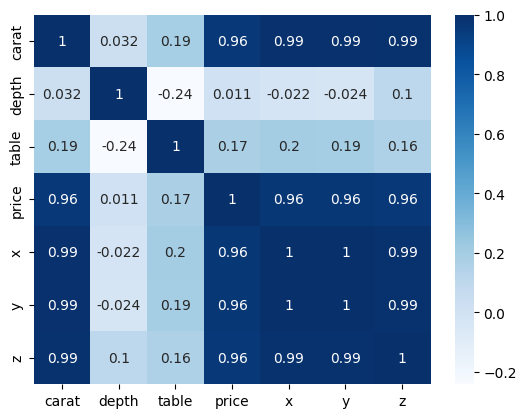

In [ ]:
import seaborn as sns

corr = df.corr(method='spearman',numeric_only=True)

sns.heatmap(corr, cmap="Blues", annot=True);

### Задание 5

Постройте scatter-plot для отражения зависимости между ценой алмаза и координатой, наиболее с ней коррелирующей. На какую зависимость она больше всего похожа?

к-ф корреляции одинаковый, построю для х

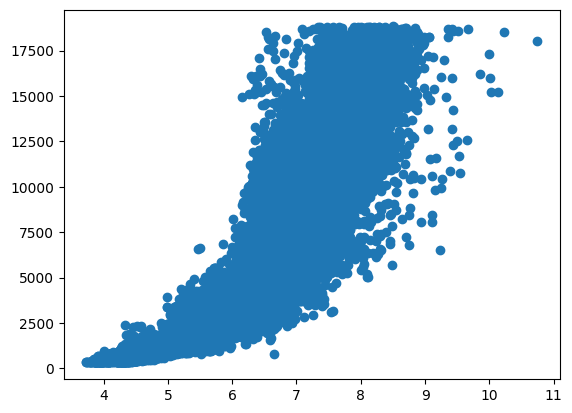

In [ ]:

import matplotlib.pyplot as plt
plt.scatter(df.x,df.price)


### Задание 6

Какой процент среди всех алмазов имеет `x` и `y` размеры, превышающие средние значения (по `x` и `y`)? Ответ округлите до целого числа.

In [ ]:
x_mean = df['x'].mean()
y_mean = df['y'].mean()

prc = len(df[(df.x > x_mean) & (df.y > y_mean) ]) / len(df) * 100
round(prc)


47

### Задание 7

Какая доля среди крупных алмазов имеет `z`-размеры, меньшие медианного? Ответ округлите до четырех знаков после запятой.

In [ ]:
z_median = df[df['carat'] > 1]['z'].median()
prc_z = len(df[df.z < z_median]) / len(df)
round(prc_z,4)

0.836

## 2) Color

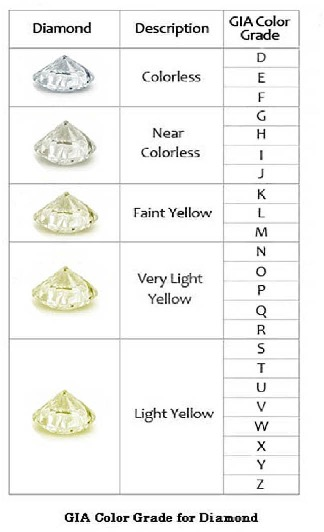

### Задание 8

К каким категориям (Description) из градации выше относятся алмазы в данных?

In [ ]:
df['color'].unique()


array(['E', 'I', 'J', 'H', 'F', 'G', 'D'], dtype=object)

Colorless и Near Colorless

### Задание 9

Нарисуйте график, отражающий зависимость стоимости алмазов от его категории цвета.

Алмазы какого цвета стоят дороже остальных?

<Axes: xlabel='color', ylabel='price'>

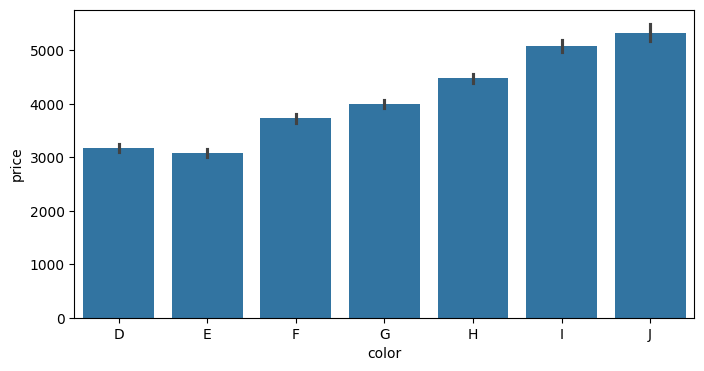

In [ ]:
plt.figure(figsize=(8, 4))
sns.barplot(x='color', y='price', data=df, order=['D', 'E', 'F', 'G', 'H', 'I', 'J'])

цвет J - near colorless

### Задание 10

Для каждого цвета алмаза вычислите медианную стоимость и медианный вес (в каратах). Отсортируйте полученную при помощи groupby таблицу по убыванию медианной стоимости.

Верно ли, что при убывании PriceMedian, сгруппированной по цвету, CaratMedian также убывает? (не возрастает)

In [ ]:
res = df.groupby('color').agg(
    PriceMedian=('price', 'median'),
    CaratMedian=('carat', 'median')
).sort_values(by='PriceMedian', ascending=False)

print(res)


       PriceMedian  CaratMedian
color                          
J           4234.5         1.11
I           3721.5         1.00
H           3449.5         0.90
F           2345.0         0.70
G           2242.0         0.70
D           1842.0         0.54
E           1741.0         0.54


### Задание 11

Вычислите среднюю стоимость алмазов по каждой тройке категорий (`cut`,`color`,`clarity`). Какие алмазы дороже остальных?

В ответе запишите тройку названий в скобках через запятую, без кавычек и пробелов. Например, (Premium,D,IF)

In [ ]:
res = df.groupby(['cut', 'color', 'clarity'])['price'].mean().sort_values(ascending=False)
print(res.head(5))


cut        color  clarity
Very Good  D      IF         10298.260870
Good       D      IF         10030.333333
Ideal      J      I1          9454.000000
Premium    D      IF          9056.500000
           J      SI2         7550.285714
Name: price, dtype: float64


***Практика***

data encoding

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53786 entries, 0 to 53804
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53786 non-null  float64
 1   cut      53786 non-null  object 
 2   color    53786 non-null  object 
 3   clarity  53786 non-null  object 
 4   depth    53786 non-null  float64
 5   table    53786 non-null  float64
 6   price    53786 non-null  float64
 7   x        53786 non-null  float64
 8   y        53786 non-null  float64
 9   z        53786 non-null  float64
dtypes: float64(7), object(3)
memory usage: 4.5+ MB


имеем три столбца не числовых, надо закодировать

In [ ]:
df['cut'].unique(),df['color'].unique(),df['clarity'].unique()

(array(['Ideal', 'Premium', 'Good', 'Very Good', 'Fair'], dtype=object),
 array(['E', 'I', 'J', 'H', 'F', 'G', 'D'], dtype=object),
 array(['SI2', 'SI1', 'VS1', 'VS2', 'VVS2', 'VVS1', 'I1', 'IF'],
       dtype=object))

все данные надо закодировать порядок, тут градация от лучшего к худшему

In [ ]:
from sklearn.preprocessing import OrdinalEncoder

cut_order = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
color_order = ['J', 'I', 'H', 'G', 'F', 'E', 'D']
clarity_order = ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']

encoder = OrdinalEncoder(categories=[cut_order, color_order, clarity_order])

cols = ['cut', 'color', 'clarity']
df[cols] = encoder.fit_transform(df[cols])


In [ ]:
df.head(3)

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,4.0,5.0,1.0,61.5,55.0,326.0,3.95,3.98,2.43
1,0.21,3.0,5.0,2.0,59.8,61.0,326.0,3.89,3.84,2.31
2,0.23,1.0,5.0,4.0,56.9,65.0,327.0,4.05,4.07,2.31


Correlation, Heat Map

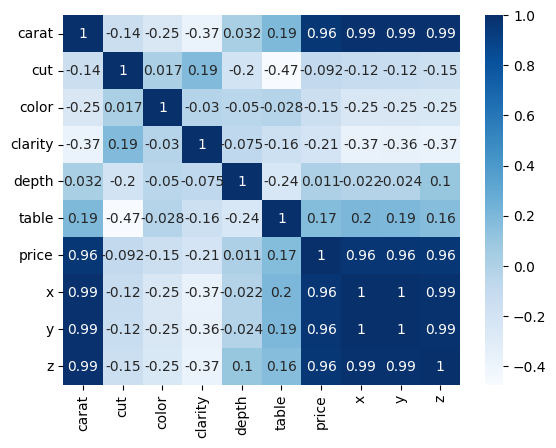

In [ ]:
corr = df.corr(method='spearman',numeric_only=True)

sns.heatmap(corr, cmap="Blues", annot=True);

Feature Importance (Linear Regression, GradientBoosting, RandomForest)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor


X = df.drop('price', axis=1)
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

rf = RandomForestRegressor(random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train, y_train)

fi_df = pd.DataFrame({
    'Feature': X.columns,
    'LinearRegression (abs coef)': np.abs(lr.coef_),
    'RandomForest': rf.feature_importances_,
    'GradientBoosting': gb.feature_importances_
})

print(fi_df.sort_values(by='RandomForest', ascending=False))


   Feature  LinearRegression (abs coef)  RandomForest  GradientBoosting
7        y                    69.374884      0.867635          0.787603
3  clarity                   845.102069      0.061956          0.057617
2    color                   526.620194      0.031852          0.027430
0    carat                  4116.886592      0.016090          0.010882
6        x                     6.430176      0.008718          0.008877
8        z                    33.500956      0.006730          0.106963
4    depth                    60.218613      0.003146          0.000195
5    table                    48.540736      0.002288          0.000083
1      cut                   136.808744      0.001584          0.000351


permutation importance

In [ ]:
from sklearn.inspection import permutation_importance
import pandas as pd

X_test_scaled = scaler.transform(X_test)

perm_lr = permutation_importance(lr, X_test_scaled, y_test, n_repeats=10, random_state=42, n_jobs=-1)
perm_rf = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)
perm_gb = permutation_importance(gb, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)

perm_df = pd.DataFrame({
    'Feature': X.columns,
    'LinearRegression': perm_lr.importances_mean,
    'RandomForest': perm_rf.importances_mean,
    'GradientBoosting': perm_gb.importances_mean
})

print(perm_df.sort_values(by='RandomForest', ascending=False))


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


   Feature  LinearRegression  RandomForest  GradientBoosting
7        y          0.000411      1.351259          0.953124
3  clarity          0.092359      0.163113          0.150697
2    color          0.036829      0.092761          0.071544
0    carat          2.162293      0.039515          0.059287
6        x          0.000026      0.019871          0.020568
8        z          0.000239      0.018053          0.136278
1      cut          0.002219      0.001166          0.001002
4    depth          0.000355      0.000736          0.000385
5    table          0.000360      0.000597          0.000022


Обучение моделей (цп - price)

In [90]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error

rf_model = RandomForestRegressor(random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

rf_preds = rf_model.predict(X_test)

print("Random Forest")
print(f"R2:       {r2_score(y_test, rf_preds):.4f}")
print(f"MAE ($):  {mean_absolute_error(y_test, rf_preds):.2f}")
print(f"MAPE (%): {mean_absolute_percentage_error(y_test, rf_preds) * 100:.2f}%")


Random Forest
R2:       0.9824
MAE ($):  263.28
MAPE (%): 6.51%


In [91]:
from sklearn.neighbors import KNeighborsRegressor

knn_model = KNeighborsRegressor(n_neighbors=7)
knn_model.fit(X_train_scaled,y_train)

knn_preds = knn_model.predict(X_test_scaled)

print("KNN")
print(f"R2:       {r2_score(y_test, knn_preds):.4f}")
print(f"MAE ($):  {mean_absolute_error(y_test, knn_preds):.2f}")
print(f"MAPE (%): {mean_absolute_percentage_error(y_test, knn_preds) * 100:.2f}%")

KNN
R2:       0.9687
MAE ($):  366.81
MAPE (%): 10.35%


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)

ridge_preds = ridge_model.predict(X_test_scaled)

print("Ridge")
print(f"R2:       {r2_score(y_test, ridge_preds):.4f}")
print(f"MAE ($):  {mean_absolute_error(y_test, ridge_preds):.2f}")
print(f"MAPE (%): {mean_absolute_percentage_error(y_test, ridge_preds) * 100:.2f}%")


Ridge
R2:       0.8920
MAE ($):  873.48
MAPE (%): 49.58%


Нелинейные модели оказались лучше линейной регрессии. Ридж не справляется и показывает плохую метрику MAPE так как модель линейная, а стоимость на алмаз - около экспоненциальная. Случайный лес обошел все модели, так как работает может игнорировать не "сильные" столбцы, а КНН работает со всеми столбцами